# EDA — Elden Ring Steam Reviews

Khám phá dữ liệu đánh giá Steam của Elden Ring. Notebook chỉ đọc dữ liệu gốc, kiểm tra chất lượng và trực quan hóa; không chỉnh sửa tệp nguồn, tiền xử lý để huấn luyện hay xây dựng mô hình.

**Nguồn:** `data/raw/elden_ring_steam_reviews.csv`

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Hỗ trợ chạy notebook từ thư mục dự án hoặc từ chính thư mục notebooks.
DATA_PATH = Path('data/raw/elden_ring_steam_reviews.csv')
if not DATA_PATH.exists():
    DATA_PATH = Path('../data/raw/elden_ring_steam_reviews.csv')
if not DATA_PATH.exists():
    raise FileNotFoundError('Không tìm thấy dữ liệu tại data/raw/elden_ring_steam_reviews.csv')

df = pd.read_csv(DATA_PATH)
print(f'Đã đọc: {DATA_PATH.resolve()}')
print(f'Kích thước: {df.shape[0]:,} dòng × {df.shape[1]} cột')

Đã đọc: C:\Users\ADMIN\Documents\Elden-Ring-Sentiment-Analysis\data\raw\elden_ring_steam_reviews.csv
Kích thước: 9,794 dòng × 16 cột


## 1. Tổng quan và kiểu dữ liệu
Hiển thị kích thước, kiểu dữ liệu pandas suy luận và thống kê mô tả để hiểu cấu trúc ban đầu.

In [2]:
print('Kiểu dữ liệu từng cột:')
display(df.dtypes.rename('Kiểu dữ liệu').to_frame())
print('Thống kê mô tả các cột số:')
display(df.describe().T)

Kiểu dữ liệu từng cột:


,Kiểu dữ liệu
id,int64
language,str
review,str
created,str
voted_up,bool
votes_up,int64
comment_count,int64
steam_purchase,bool
recieved_for_free,bool
written_during_early_access,bool


Thống kê mô tả các cột số:


,count,mean,std,min,25%,50%,75%,max
id,9794.0,1.329966e+08,724635.350145,131801971.0,1.323394e+08,132995861.0,1.336450e+08,134238864.0
votes_up,9794.0,1.107617e+00,33.576724,0.0,0.000000e+00,0.0,0.000000e+00,2410.0
comment_count,9794.0,3.512355e-02,0.428238,0.0,0.000000e+00,0.0,0.000000e+00,25.0
author_num_games_owned,9794.0,1.090373e+02,206.868437,1.0,2.300000e+01,56.0,1.230000e+02,6458.0
author_num_reviews,9794.0,8.867266e+00,18.287920,1.0,2.000000e+00,4.0,9.000000e+00,790.0
author_playtime_forever,9794.0,8.534752e+03,9082.240954,5.0,3.430250e+03,6449.5,1.061675e+04,160118.0
author_playtime_last_two_weeks,9794.0,9.611297e+02,1466.911509,0.0,0.000000e+00,322.0,1.384750e+03,20082.0
author_playtime_at_review,9794.0,7.249124e+03,8702.430291,5.0,2.038000e+03,5185.0,9.180750e+03,160118.0


**Nhận xét:** Dữ liệu có 9.794 đánh giá và 16 thuộc tính. `voted_up` là biến nhị phân về việc đề xuất trò chơi; `review` chứa nội dung văn bản. Các cột thời gian và thông tin người chơi là dữ liệu bổ sung, không phải nội dung cảm xúc trực tiếp.

## 2. Thiếu dữ liệu, trùng lặp và giá trị bất thường
Kiểm tra ô thiếu, dòng/mã đánh giá trùng, giá trị số âm ở các bộ đếm/thời lượng, giá trị nhãn ngoài tập True/False và thời gian không phân tích được. Đây là các cờ kiểm tra sơ bộ, không tự sửa dữ liệu.

In [3]:
missing = df.isna().sum()
review_blank = df['review'].isna() | df['review'].astype('string').str.strip().eq('').fillna(True)
print('Số ô thiếu theo cột (chỉ hiện cột có thiếu):')
display(missing[missing > 0].rename('Ô thiếu').to_frame())
print(f'Số đánh giá thiếu/trống (tính cả chuỗi chỉ có khoảng trắng): {int(review_blank.sum())}')

duplicate_rows = int(df.duplicated().sum())
duplicate_ids = int(df['id'].duplicated().sum()) if 'id' in df.columns else None
print(f'Dòng trùng hoàn toàn: {duplicate_rows}')
print(f'Mã id trùng: {duplicate_ids}')

numeric_checks = [
    'votes_up', 'comment_count', 'author_num_games_owned',
    'author_num_reviews', 'author_playtime_forever',
    'author_playtime_last_two_weeks', 'author_playtime_at_review'
]
negative_counts = {col: int((pd.to_numeric(df[col], errors='coerce') < 0).sum())
                   for col in numeric_checks if col in df.columns}
boolean_checks = ['voted_up', 'steam_purchase', 'recieved_for_free', 'written_during_early_access']
unexpected_boolean_values = {
    col: sorted(df[col].dropna().astype(str).unique().tolist())
    for col in boolean_checks if col in df.columns
}
date_checks = ['created', 'author_last_played']
invalid_dates = {col: int(pd.to_datetime(df[col], errors='coerce').isna().sum())
                 for col in date_checks if col in df.columns}

print('Giá trị âm trong các cột số (nên bằng 0):', negative_counts)
recent_playtime_exceeds_total = int((df['author_playtime_last_two_weeks'] > df['author_playtime_forever']).sum())
print('Thời gian chơi 2 tuần gần nhất lớn hơn tổng thời gian chơi:', recent_playtime_exceeds_total)
print('Các giá trị quan sát được ở cột dạng boolean:', unexpected_boolean_values)
print('Thời gian không đọc được:', invalid_dates)
print('Khoảng thời gian đánh giá:', pd.to_datetime(df['created'], errors='coerce').min(), 'đến',
      pd.to_datetime(df['created'], errors='coerce').max())

Số ô thiếu theo cột (chỉ hiện cột có thiếu):


,Ô thiếu
review,29


Số đánh giá thiếu/trống (tính cả chuỗi chỉ có khoảng trắng): 31
Dòng trùng hoàn toàn: 0
Mã id trùng: 0
Giá trị âm trong các cột số (nên bằng 0): {'votes_up': 0, 'comment_count': 0, 'author_num_games_owned': 0, 'author_num_reviews': 0, 'author_playtime_forever': 0, 'author_playtime_last_two_weeks': 0, 'author_playtime_at_review': 0}
Thời gian chơi 2 tuần gần nhất lớn hơn tổng thời gian chơi: 12
Các giá trị quan sát được ở cột dạng boolean: {'voted_up': ['False', 'True'], 'steam_purchase': ['False', 'True'], 'recieved_for_free': ['False', 'True'], 'written_during_early_access': ['False']}
Thời gian không đọc được: {'created': 0, 'author_last_played': 0}
Khoảng thời gian đánh giá: 2023-01-29 14:32:52 đến 2023-03-07 14:19:11


**Nhận xét:** Có 31 đánh giá thiếu/trống nội dung (29 ô NA và 2 ô chỉ có khoảng trắng); các cột khác đầy đủ. Không có dòng trùng hoàn toàn, `id` trùng, giá trị âm, nhãn boolean lạ hay thời gian sai định dạng. Có 12 bản ghi có thời gian chơi 2 tuần gần nhất lớn hơn tổng thời gian chơi; đây là bất nhất cần lưu ý, không tự ý sửa trong EDA.

## 3. Phân phối nhãn `voted_up`
`True` nghĩa là người đánh giá đề xuất trò chơi, `False` nghĩa là không đề xuất. Tỷ lệ được tính trên toàn bộ bản ghi có nhãn hợp lệ.

Số lượng và tỷ lệ nhãn:


,Số đánh giá,Tỷ lệ (%)
voted_up,,
True,9201,93.95
False,593,6.05


Tỷ lệ lớp đa số / lớp thiểu số: 15.52:1


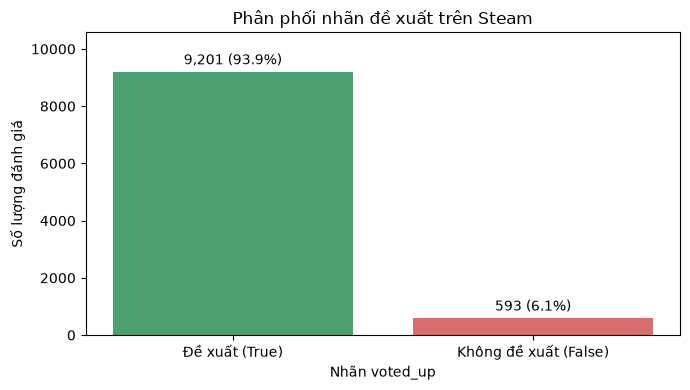

In [4]:
label_counts = df['voted_up'].value_counts(dropna=False).reindex([True, False], fill_value=0)
label_percent = label_counts / label_counts.sum() * 100
majority_ratio = (label_counts.max() / label_counts.min()
                  if label_counts.min() else float('inf'))
print('Số lượng và tỷ lệ nhãn:')
display(pd.DataFrame({'Số đánh giá': label_counts, 'Tỷ lệ (%)': label_percent.round(2)}))
print(f'Tỷ lệ lớp đa số / lớp thiểu số: {majority_ratio:.2f}:1')

fig, ax = plt.subplots(figsize=(7, 4))
labels = ['Đề xuất (True)', 'Không đề xuất (False)']
bars = ax.bar(labels, label_counts.values, color=['#4C9F70', '#D96C6C'])
ax.set_title('Phân phối nhãn đề xuất trên Steam')
ax.set_ylabel('Số lượng đánh giá')
ax.set_xlabel('Nhãn voted_up')
ax.bar_label(bars, labels=[f'{n:,} ({p:.1f}%)' for n, p in zip(label_counts, label_percent)], padding=3)
ax.set_ylim(0, label_counts.max() * 1.15)
plt.tight_layout()
plt.show()

**Nhận xét:** Nhãn lệch mạnh về phía đề xuất: 9.201 đánh giá tích cực và 593 đánh giá không đề xuất (xấp xỉ 15,5:1). Vì vậy, độ chính xác tổng thể đơn lẻ có thể gây hiểu nhầm khi đánh giá mô hình ở giai đoạn sau.

## 4. Độ dài nội dung đánh giá
Độ dài được tính trên bản sao trong bộ nhớ bằng số ký tự và số từ; các giá trị thiếu được loại khỏi phần thống kê/biểu đồ độ dài, không ghi lại vào tệp gốc. Histogram giới hạn trục ở phân vị 99 để phần lớn phân phối dễ quan sát hơn.

,Số ký tự,Số từ
count,9763.00,9763.0
mean,155.72,28.4
std,493.89,89.0
min,1.00,1.0
25%,11.00,2.0
50%,31.00,6.0
75%,97.00,18.0
95%,674.80,119.0
max,7983.00,1551.0


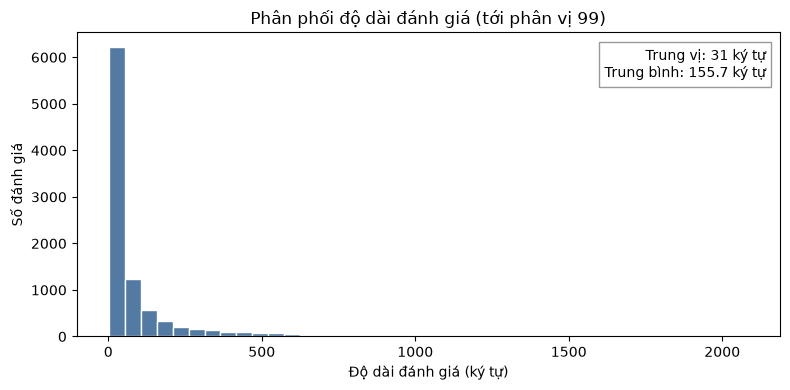

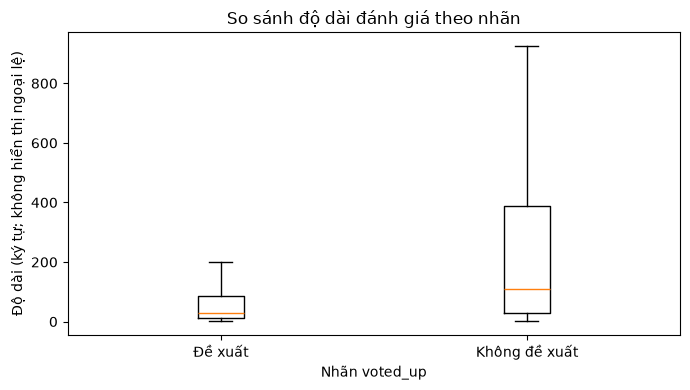

In [5]:
review_available = df['review'].notna() & df['review'].astype('string').str.strip().ne('').fillna(False)
review_text = df.loc[review_available, 'review'].astype(str)
review_chars = review_text.str.len()
review_words = review_text.str.split().str.len()
length_summary = pd.DataFrame({
    'Số ký tự': review_chars.describe(percentiles=[0.25, 0.5, 0.75, 0.95]).round(2),
    'Số từ': review_words.describe(percentiles=[0.25, 0.5, 0.75, 0.95]).round(2),
})
display(length_summary)

plot_limit = review_chars.quantile(0.99)
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(review_chars[review_chars <= plot_limit], bins=40, color='#527AA3', edgecolor='white')
ax.set_title('Phân phối độ dài đánh giá (tới phân vị 99)')
ax.set_xlabel('Độ dài đánh giá (ký tự)')
ax.set_ylabel('Số đánh giá')
ax.text(0.98, 0.95, f'Trung vị: {review_chars.median():.0f} ký tự\n'
        f'Trung bình: {review_chars.mean():.1f} ký tự',
        transform=ax.transAxes, ha='right', va='top',
        bbox={'facecolor': 'white', 'alpha': 0.8, 'edgecolor': 'gray'})
plt.tight_layout()
plt.show()

length_by_label = pd.DataFrame({'voted_up': df.loc[review_available, 'voted_up'],
                               'số ký tự': review_chars})
fig, ax = plt.subplots(figsize=(7, 4))
groups = [length_by_label.loc[length_by_label['voted_up'] == value, 'số ký tự']
          for value in [True, False]]
ax.boxplot(groups, tick_labels=['Đề xuất', 'Không đề xuất'], showfliers=False)
ax.set_title('So sánh độ dài đánh giá theo nhãn')
ax.set_xlabel('Nhãn voted_up')
ax.set_ylabel('Độ dài (ký tự; không hiển thị ngoại lệ)')
plt.tight_layout()
plt.show()

**Nhận xét:** Độ dài đánh giá phân tán và thường lệch phải; xem trung vị cùng các phân vị sẽ đại diện tốt hơn chỉ dùng trung bình. Biểu đồ hộp giúp so sánh độ dài giữa hai nhãn nhưng riêng độ dài không đủ để kết luận sắc thái cảm xúc.

## 5. Số lượng đánh giá theo ngày
Biểu đồ dùng ngày tạo đánh giá (`created`) để quan sát phạm vi và mức độ tập trung theo thời gian của mẫu dữ liệu.

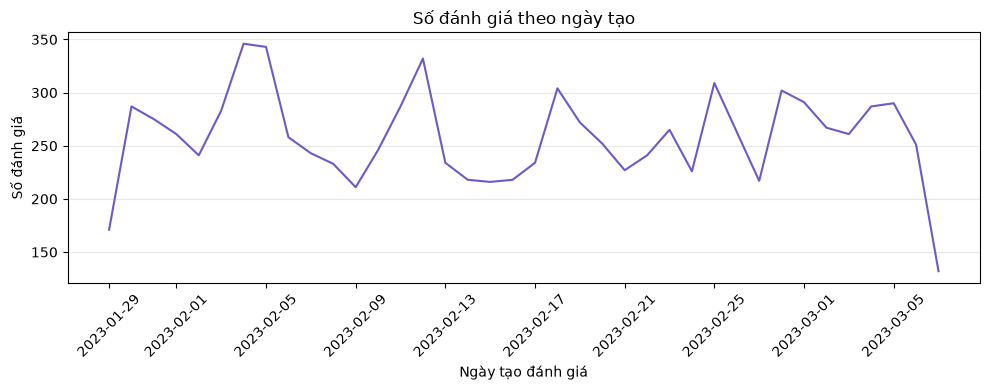

Ngày có đánh giá trong dữ liệu: 38


In [6]:
created_at = pd.to_datetime(df['created'], errors='coerce')
daily_counts = created_at.dropna().dt.date.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(daily_counts.index, daily_counts.values, color='#6A5ACD', linewidth=1.5)
ax.set_title('Số đánh giá theo ngày tạo')
ax.set_xlabel('Ngày tạo đánh giá')
ax.set_ylabel('Số đánh giá')
ax.tick_params(axis='x', rotation=45)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()
print(f'Ngày có đánh giá trong dữ liệu: {len(daily_counts)}')

**Nhận xét:** Dữ liệu chỉ bao phủ một khoảng thời gian giới hạn, vì vậy xu hướng theo ngày phản ánh mẫu thu thập này, không nhất thiết đại diện cho toàn bộ người chơi Elden Ring trên Steam.

## Kết luận EDA và đề xuất với 31 đánh giá thiếu nội dung
- Nhãn `voted_up` có thể dùng làm nhãn phân loại tích cực/không đề xuất, nhưng mất cân bằng đáng kể.
- Có 31 bản ghi thiếu `review` (khoảng 0,32% dữ liệu). Không nên tự tạo nội dung thay thế. Giữ nguyên tệp gốc; trong phân tích cần văn bản, tạo tập làm việc riêng và loại các dòng thiếu `review`, đồng thời ghi nhận số dòng bị loại. Các bản ghi này vẫn có thể hữu ích cho phân tích dựa trên metadata/nhãn.
- Notebook chỉ thực hiện EDA; chưa tiền xử lý dữ liệu cho huấn luyện và chưa xây dựng mô hình.